# Robust bias correction: `linear` vs `theilsen` vs `ransac` на синтетике с выбросами

**Цель:** проверить, как три режима `LinearBiasCorrector` (регрессоры OLS / Theil–Sen / RANSAC)
справляются с систематическим смещением **в присутствии выбросов**.


**Метрика** — `lowess_metric.calculate_lowess_metric` (отклонение площади LOWESS от идеала `y=x`,
`quality_score`, плюс MAE/RMSE/R²). **На рисунках** — линия LOWESS, плотность (KDE)

корректор обучается на **train**, применяется к **test**.

In [9]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.ndimage import gaussian_filter
from statsmodels.nonparametric.smoothers_lowess import lowess

warnings.filterwarnings('ignore')

# --- корректор берём СТРОГО из пакета в .../regression-bias-corrector/src ---
_HERE       = Path.cwd().resolve()               # .../regression-bias-corrector/notebooks
_PKG_SRC    = _HERE.parent / 'src'               # .../regression-bias-corrector/src
_METRICS_DIR = _HERE.parents[1]                  # .../Bias_corrector  (там lowess_metric.py)

if not (_PKG_SRC / 'regression_bias_corrector').is_dir():      # страховка, если запуск не из notebooks/
    _PKG_SRC     = Path(r'C:\Users\1\.unsloth\studio\sandbox\Bias_corrector\regression-bias-corrector\src')
    _METRICS_DIR = Path(r'C:\Users\1\.unsloth\studio\sandbox\Bias_corrector')

for _p in (str(_PKG_SRC), str(_METRICS_DIR)):    # insert(0) -> пакет из src важнее любой pip-версии
    if _p not in sys.path:
        sys.path.insert(0, _p)

from regression_bias_corrector import LinearBiasCorrector
import regression_bias_corrector as rbc
from lowess_metric import calculate_lowess_metric

print('regression-bias-corrector:', rbc.__version__)
print('класс корректора импортирован из:', rbc.__file__)
assert 'regression-bias-corrector' in os.path.normcase(rbc.__file__), \
    f'Внимание: импортирован пакет не из src: {rbc.__file__}'

IMAGES = 'images'; os.makedirs(IMAGES, exist_ok=True)

regression-bias-corrector: 0.1.dev28+g64fa3b130.d20260813
класс корректора импортирован из: C:\Users\1\.unsloth\studio\sandbox\Bias_corrector\regression-bias-corrector\src\regression_bias_corrector\__init__.py


## 1. Синтетические данные: смещение + выбросы

`true_age` — хронологический возраст, `bioage_raw` — «предсказание модели»: сжатое к среднему
(наклон < 1 → классическое regression-to-the-mean) и со сдвигом. Это то смещение, которое и должен
убрать корректор. Отдельно задаём долю выбросов, чтобы потом ею управлять.

In [2]:
def make_dataset(seed=42, n=500, slope=0.55, intercept=18.0, noise=3.0, outlier_frac=0.06):
    rng = np.random.default_rng(seed)
    true_age = np.clip(rng.normal(40, 10, n), 18, 62)
    bioage_raw = slope * true_age + intercept + rng.normal(0, noise, n)

    # Величины выбросов задаём один раз на все точки: тогда frac=0.10 включает в себя
    # те же точки и с тем же сдвигом, что и frac=0.05 -> доля строго вложенная, sweep чистый.
    pool = rng.permutation(n)
    shift = rng.choice([-1, 1], n) * rng.uniform(12, 30, n)
    n_out = int(round(outlier_frac * n))
    bioage_raw[pool[:n_out]] += shift[:n_out]

    perm = rng.permutation(n); n_tr = int(0.7 * n)         # train/test сплит
    tr, te = perm[:n_tr], perm[n_tr:]
    return dict(true_age=true_age, bioage_raw=bioage_raw, slope=slope,
                y_train=true_age[tr], x_train=bioage_raw[tr],
                y_test=true_age[te], x_test=bioage_raw[te], n_out=n_out)

d = make_dataset()
print(f"n={len(d['true_age'])}, выбросов={d['n_out']}, train/test={len(d['y_train'])}/{len(d['y_test'])}")
print(f"истинный обратный наклон (эталон для корректора) a* = {1/d['slope']:.3f}")
print(f"сырое смещение: mean(bioage-true) = {(d['bioage_raw']-d['true_age']).mean():+.2f}, "
      f"slope(true~bioage) = {np.polyfit(d['bioage_raw'], d['true_age'], 1)[0]:.3f}")

n=500, выбросов=30, train/test=350/150
истинный обратный наклон (эталон для корректора) a* = 1.818
сырое смещение: mean(bioage-true) = -0.06, slope(true~bioage) = 0.767


## 2. Три метода коррекции и их метрики

residual_threshold=8, min_samples=0.5 для RANSAC осмысленные настройки:
по умолчанию порог = MAD-оценка от остатков, которая при сильном смещении съедает и выбросы тоже
Theil–Sen перебирает слишком много подвыборок на полном объёме, поэтому фиксируем `max_subpopulation`.

Во всех ячейках коррекция вызывается из пакета — `LinearBiasCorrector` из 
`src/regression_bias_corrector` (`fit(true, pred)` / `predict(pred)`); 


In [10]:
METHODS = {
    'raw':      None,
    'linear':   ('linear',   None),
    'theilsen': ('theilsen', dict(random_state=42, max_subpopulation=2000)),
    'ransac':   ('ransac',   dict(random_state=42, residual_threshold=8, min_samples=0.5)),
}

def correct(d, spec):
    if spec is None:
        return d['x_test'], np.nan
    kind, params = spec
    c = LinearBiasCorrector(regressor_type=kind, regressor_params=params)
    c.fit(d['y_train'], d['x_train'])          # fit(true, pred) — как в example.ipynb
    return c.predict(d['x_test']), float(c.rotation_lr)

rows = {}
for name, spec in METHODS.items():
    y_hat, a = correct(d, spec)
    m = calculate_lowess_metric(true_values=d['y_test'], pred_values=y_hat)   # метрика из lowess_metric.py
    m['a_rotation'] = a
    rows[name] = m

df = pd.DataFrame(rows).T
df['a_err_%'] = 100 * (df['a_rotation'] / (1 / d['slope']) - 1)               # насколько восстановлен наклон
print(f"эталонный a* = {1/d['slope']:.3f}\n")
df[['a_rotation', 'a_err_%', 'lowess_deviation', 'lowess_score', 'balance_ratio',
   'quality_score', 'mae', 'rmse', 'r2']].round(4)

эталонный a* = 1.818



,a_rotation,a_err_%,lowess_deviation,lowess_score,balance_ratio,quality_score,mae,rmse,r2
raw,NaN,NaN,0.03402,0.934223,0.326644,0.706374,4.951216,7.376947,0.435594
linear,2.091989,15.059376,0.118111,0.789605,0.404674,0.353284,7.200667,11.907387,-0.470521
theilsen,1.831269,0.719798,0.091538,0.832704,0.395819,0.477054,6.071042,10.411587,-0.124273
ransac,1.826567,0.461178,0.105239,0.810197,0.458652,0.451274,5.991824,10.379552,-0.117366


### Что читаем из таблицы
- `lowess_deviation` — отклонение площади LOWESS от идеала (0 = идеально), `quality_score` — свёртка (больше = лучше).
- `a_err_%` — ошибка восстановления наклона: прямой индикатор робастности к выбросам.

## 3. KDE + identity + LOWESS

Стилистика как на референсном слайде: облако плотности (2D KDE) + точки + пунктир тождества + crimson LOWESS.

Два технических решения, без которых картинка получается хуже референса:

- **Общие оси по перцентилям 0.5–99.5**, а не по min/max. Иначе единичный выброс после
  растяжения `a≈1.8` раздувает диапазон до 0–124, всё облако сжимается в центр и структура пропадает.
- **LOWESS рисуется на `frac=0.3` (как в метрике) с отсечкой краёв 2–98 перцентиля.** На самых краях
  локальная регрессия опирается на несколько точек и даёт «крюк» против тренда; он — артефакт
  краевого эффекта, а не свойство коррекции. `frac` оставлен равным 0.3 специально, чтобы линия на
  рисунке соответствовала той же кривой, по которой считается `lowess_deviation`.

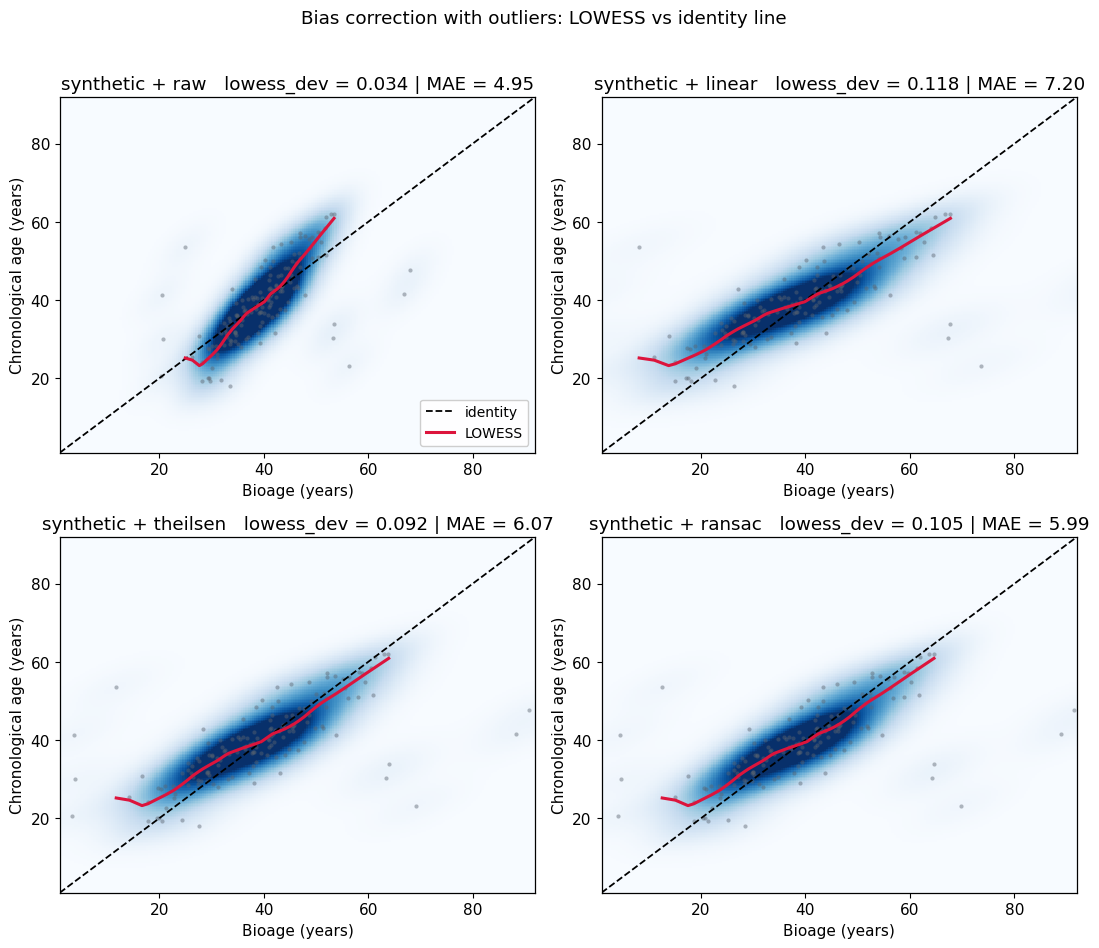

In [11]:
plt.rcParams.update({'font.size': 11, 'axes.linewidth': 0.9})
LOWESS_FRAC = 0.3          # та же frac, что и в calculate_lowess_metric -> линия = оцениваемая кривая
TRIM_PCT    = (2, 98)      # отсечение краевого «крюка» LOWESS
AXIS_PCT    = (0.5, 99.5)  # общие границы осей по перцентилям вместо min/max

def density_bg(ax, x, y, lo, hi, n=220, sigma=3.0, cmap='Blues', vmax_q=0.98):
    """Мягкое синее облако плотности на фоне — как в приложенном рисунке."""
    grid = np.linspace(lo, hi, n)
    X, Y = np.meshgrid(grid, grid)
    Z = gaussian_kde(np.vstack([x, y]))(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    Z = gaussian_filter(Z, sigma=sigma)
    ax.pcolormesh(X, Y, Z, cmap=cmap, vmin=0, vmax=np.quantile(Z[Z > 0], vmax_q),
                  shading='auto', zorder=0)

def panel(ax, x, y, title, lo, hi, legend=False):
    density_bg(ax, x, y, lo, hi)
    ax.scatter(x, y, s=9, c='#5b6470', alpha=0.45, linewidths=0, zorder=3)
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.3, label='identity', zorder=4)
    lx, ly = lowess(y, x, frac=LOWESS_FRAC, return_sorted=True).T
    keep = (lx >= np.percentile(x, TRIM_PCT[0])) & (lx <= np.percentile(x, TRIM_PCT[1]))
    ax.plot(lx[keep], ly[keep], color='crimson', lw=2.2, label='LOWESS', zorder=5)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel('Bioage (years)'); ax.set_ylabel('Chronological age (years)')
    ax.set_title(title)
    if legend:
        ax.legend(loc='lower right', framealpha=0.95, fontsize=10)

preds = {name: correct(d, spec)[0] for name, spec in METHODS.items()}
pooled = np.concatenate(list(preds.values()) + [d['y_test']])
lo, hi = np.percentile(pooled, AXIS_PCT)
pad = 0.03 * (hi - lo); lo, hi = lo - pad, hi + pad

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for i, (ax, name) in enumerate(zip(axes.ravel(), METHODS)):
    panel(ax, preds[name], d['y_test'],
          f"synthetic + {name}   lowess_dev = {df.loc[name,'lowess_deviation']:.3f} | MAE = {df.loc[name,'mae']:.2f}",
          lo, hi, legend=(i == 0))
fig.suptitle('Bias correction with outliers: LOWESS vs identity line', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(os.path.join(IMAGES, 'robust_bias_correction_panels.png'), dpi=150, bbox_inches='tight')
plt.show()


## 4. Устойчивость к выбросам

Один запуск слишком шумный (разброс `a` сам по себе ~0.1), поэтому каждая точка — **среднее по 10 seed'ам**,
а на наклоне показан и разброс ±std. Именно рост std у неустойчивого метода и есть сигнал деградации,
а не отдельное «упавшее» значение. Коррекция везде вызывается из пакета (`LinearBiasCorrector`),
отдельно сравнивается RANSAC с явным `residual_threshold=8` и с дефолтным порогом.

In [13]:
FRACS = [0.0, 0.02, 0.05, 0.10, 0.20, 0.30]
SEEDS = range(10)

# Каждый вариант = режим regressor_type внутри LinearBiasCorrector (пакет); sklearn напрямую не зовём.
VARIANTS = {
    'linear':         ('linear',   None),
    'theilsen':       ('theilsen', dict(random_state=42, max_subpopulation=2000)),
    'ransac':         ('ransac',   dict(random_state=42, residual_threshold=8, min_samples=0.5)),
    'ransac default': ('ransac',   dict(random_state=42)),
}
a_star = 1 / d['slope']

recs = []
for frac in FRACS:
    for seed in SEEDS:
        dd = make_dataset(seed=seed, outlier_frac=frac)
        for name, spec in VARIANTS.items():
            y_hat, a = correct(dd, spec)          # <-- коррекция из пакета
            m = calculate_lowess_metric(true_values=dd['y_test'], pred_values=y_hat)
            recs.append(dict(frac=frac, seed=seed, method=name, a=a,
                             dev=m['lowess_deviation'], quality=m['quality_score'], mae=m['mae']))

sweep = pd.DataFrame(recs)
agg = (sweep.groupby(['frac', 'method'])
            .agg(a=('a', 'mean'), a_std=('a', 'std'),
                 abs_a_err=('a', lambda s: float(np.mean(np.abs(s - a_star)))),
                 mae=('mae', 'mean'), dev=('dev', 'mean'), quality=('quality', 'mean'))
            .reset_index())

print(f"эталон a* = {a_star:.3f}   (10 seed'ов на каждую долю выбросов)\n")
print('наклон a: среднее ± std')
print(agg.assign(aai=lambda x: x.a.round(3).astype(str) + ' ± ' + x.a_std.round(3).astype(str))
         .pivot(index='frac', columns='method', values='aai').to_string())
print('\nсредняя |ошибка наклона|, %')
print((100 * agg.pivot(index='frac', columns='method', values='abs_a_err') / a_star).round(2).to_string())


эталон a* = 1.818   (10 seed'ов на каждую долю выбросов)

наклон a: среднее ± std
method         linear         ransac ransac default       theilsen
frac                                                              
0.00    1.823 ± 0.079  1.818 ± 0.077  1.827 ± 0.184  1.828 ± 0.098
0.02    1.818 ± 0.069  1.835 ± 0.061  1.771 ± 0.189  1.839 ± 0.061
0.05    1.814 ± 0.078   1.86 ± 0.076  1.912 ± 0.292  1.869 ± 0.064
0.10    1.829 ± 0.155  1.804 ± 0.066  1.939 ± 0.341  1.803 ± 0.087
0.20    1.885 ± 0.247  1.851 ± 0.081   1.91 ± 0.188  1.864 ± 0.125
0.30    1.859 ± 0.211  1.842 ± 0.048  1.873 ± 0.212  1.869 ± 0.105

средняя |ошибка наклона|, %
method  linear  ransac  ransac default  theilsen
frac                                            
0.00      3.51    3.37            7.81      4.05
0.02      3.26    2.73            8.49      2.84
0.05      3.14    3.35           13.76      3.71
0.10      6.52    3.00           14.13      3.93
0.20     13.16    3.61            7.90      6.33
0.30      

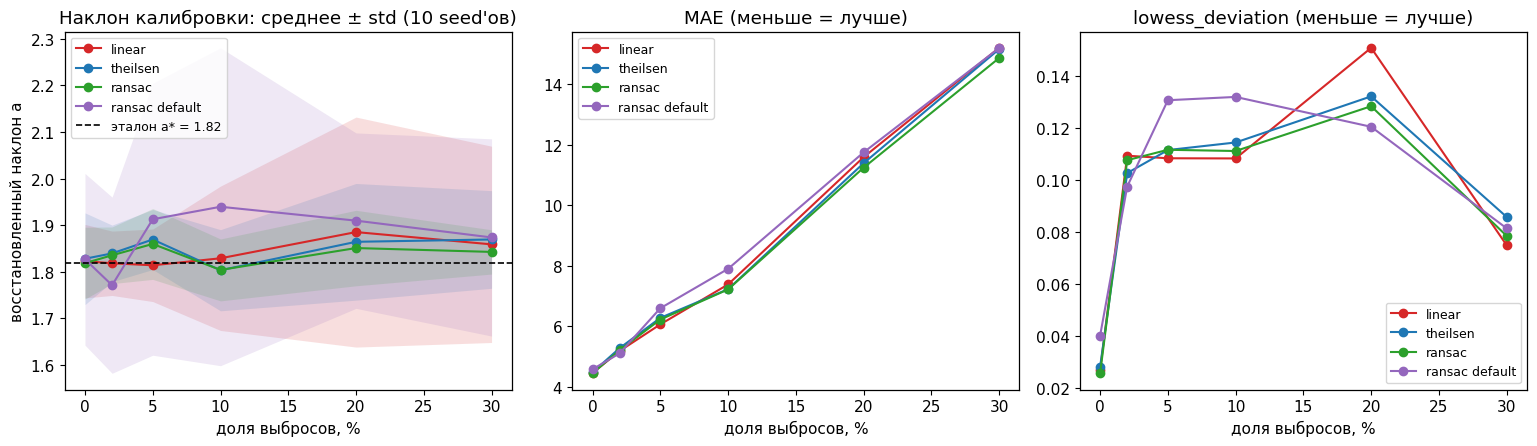

In [14]:
COLORS = {'linear': '#d62728', 'theilsen': '#1f77b4', 'ransac': '#2ca02c', 'ransac default': '#9467bd'}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

ax = axes[0]
for name in VARIANTS:
    s = agg[agg.method == name]
    ax.plot(100 * s.frac, s.a, 'o-', color=COLORS[name], label=name)
    ax.fill_between(100 * s.frac, s.a - s.a_std, s.a + s.a_std, color=COLORS[name], alpha=0.15, lw=0)
ax.axhline(a_star, ls='--', c='k', lw=1.2, label=f'эталон a* = {a_star:.2f}')
ax.set_xlabel('доля выбросов, %'); ax.set_ylabel('восстановленный наклон a')
ax.set_title('Наклон калибровки: среднее ± std (10 seed\'ов)'); ax.legend(fontsize=9)

for k, (col, ttl) in enumerate([('mae', 'MAE (меньше = лучше)'),
                                ('dev', 'lowess_deviation (меньше = лучше)')], start=1):
    ax = axes[k]
    for name in VARIANTS:
        s = agg[agg.method == name]
        ax.plot(100 * s.frac, s[col], 'o-', color=COLORS[name], label=name)
    ax.set_xlabel('доля выбросов, %'); ax.set_title(ttl); ax.legend(fontsize=9)

fig.tight_layout()
fig.savefig(os.path.join(IMAGES, 'robust_bias_correction_sweep.png'), dpi=150, bbox_inches='tight')
plt.show()

In [15]:
for col, ttl in [('mae', 'MAE'), ('dev', 'lowess_deviation'), ('quality', 'quality_score')]:
    print(f'{ttl} по доле выбросов (среднее по {len(list(SEEDS))} seed\'ам)')
    print(agg.pivot(index='frac', columns='method', values=col).round(3).to_string(), '\n')

print('Вывод: у linear разброс a растёт с долей выбросов (нестабильная калибровка), '
      'theilsen и ransac с явным residual_threshold держат a около эталона, '
      'а ransac с дефолтным порогом — самый неустойчивый (автопорог из MAD принимает выбросы за инлаеры).')

MAE по доле выбросов (среднее по 10 seed'ам)
method  linear  ransac  ransac default  theilsen
frac                                            
0.00     4.460   4.451           4.583     4.484
0.02     5.189   5.217           5.111     5.282
0.05     6.068   6.228           6.601     6.282
0.10     7.388   7.224           7.904     7.231
0.20    11.596  11.248          11.754    11.396
0.30    15.211  14.874          15.203    15.168 

lowess_deviation по доле выбросов (среднее по 10 seed'ам)
method  linear  ransac  ransac default  theilsen
frac                                            
0.00     0.027   0.026           0.040     0.028
0.02     0.109   0.108           0.098     0.103
0.05     0.108   0.112           0.131     0.112
0.10     0.108   0.111           0.132     0.114
0.20     0.151   0.128           0.121     0.132
0.30     0.075   0.079           0.081     0.086 

quality_score по доле выбросов (среднее по 10 seed'ам)
method  linear  ransac  ransac default  theilsen
frac 